# Laboratorium 3: Od tokenów do reprezentacji wektorowych

W tym laboratorium porównamy rzadkie i gęste reprezentacje wektorowe oraz sprawdzimy, jak zachowują się w zadaniach opartych na podobieństwie tekstów.

Porównujemy:

- TF-IDF,
- `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`,
- `intfloat/multilingual-e5-small`.

Główne pytanie laboratorium:

**Czy bliskość dwóch tekstów w przestrzeni wektorowej odpowiada podobieństwu, którego potrzebujemy w konkretnym zadaniu NLP?**


## Po tych zajęciach student potrafi

- wyjaśnić różnicę między rzadką i gęstą reprezentacją wektorową;
- obliczyć i zinterpretować podobieństwo cosinusowe;
- wygenerować reprezentacje tekstu za pomocą modelu embeddingowego;
- zaimplementować wyszukiwanie najbliższych sąsiadów;
- ocenić jakość lokalnego sąsiedztwa;
- zbudować prosty benchmark wyszukiwania;
- zastosować PCA do analizy przestrzeni reprezentacji;
- rozpoznać przypadki, w których wysokie podobieństwo wektorowe nie odpowiada wymaganiom zadania;
- porównać jakość reprezentacji z jej kosztem obliczeniowym;
- uzasadnić wybór reprezentacji dla konkretnego zastosowania.


## Dane

Pracujemy na zbiorze PolEmo 2.0 wykorzystywanym w poprzednich laboratoriach.

Jeżeli istnieje plik:

```text
artifacts/polemo2_clean.parquet
```

należy użyć tej wersji danych. Jeśli pliku nie ma, proszę wrócić do Lab 1 i go przygotować.

W tym laboratorium nie używamy zbioru testowego do wyboru reprezentacji ani do strojenia eksperymentów.


## Ustawienia wstępne

Wymagane biblioteki:

```bash
pip install pandas numpy matplotlib scikit-learn pyarrow sentence-transformers
```

Kod startowy obejmuje wyłącznie importy, stałe i wczytanie danych. Implementacja eksperymentów należy do Państwa.


In [63]:
! pip install --upgrade pip

In [64]:
! pip install -U sentence-transformers

In [65]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

from sentence_transformers import SentenceTransformer

RANDOM_STATE = 42
SAMPLE_SIZE = 1000

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

MODEL_A = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MODEL_B = "intfloat/multilingual-e5-small"

pd.set_option("display.max_colwidth", 180)


In [66]:
DATA_PATH = ARTIFACTS / "polemo2_clean.parquet"
assert DATA_PATH.exists(), "Brak artifacts/polemo2_clean.parquet. Proszę wykonać Lab 1."

data = pd.read_parquet(DATA_PATH).dropna(subset=["text", "target"]).reset_index(drop=True)
assert set(data["target"]) == {"plus", "minus", "zero", "amb"}

train_df = data[data["split"] == "train"].reset_index(drop=True)  # tylko train, bez validation i test
print(train_df.shape)
display(train_df.head())

(5783, 5)


,text,target,split,text_norm,is_duplicate_in_split
0,"Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą staruszką , i twierdz...",plus,train,"super lekarz i człowiek przez duże c . bardzo duże doświadczenie i trafne diagnozy . wielka cierpliwość do ludzi starszych . od lat opiekuje się moją mamą staruszką , i twierdz...",False
1,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,minus,train,bardzo olewcze podejscie do pacjenta . przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,False
2,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora nie mam zastrzeżeń ...",amb,train,"lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . do pana doktora nie mam zastrzeżeń ...",False
3,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie trzeba wychodzić z dom...",zero,train,""" konsumenci oczywiście kierują się ceną . te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . jest to mniej krępujące , nie trzeba wychodzić z dom...",False
4,"Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikatna , bardzo miła , c...",plus,train,"pani doktor iwona jest profesjonalistką w każdym calu : ) idąc do stomatologa zawsze czuję przeraźliwy strach . pani doktor iwona jest wyrozumiała i delikatna , bardzo miła , c...",False


# Zadanie 1: TF-IDF i podobieństwo cosinusowe

Proszę rozpocząć od tekstów:

```text
A = "hotel czysty wygodny"
B = "hotel bardzo czysty"
C = "samochód szybki sportowy"
```

Proszę zaimplementować:

1. reprezentację TF-IDF;
2. tabelę wartości TF-IDF;
3. macierz podobieństwa cosinusowego;
4. wskazanie najbardziej podobnej pary.

Następnie proszę powtórzyć eksperyment dla:

```text
A = "Hotel był bardzo dobry."
B = "Obiekt noclegowy zrobił na mnie świetne wrażenie."
C = "Hotel był bardzo zły."
```

Przed uruchomieniem kodu proszę zapisać, która para powinna być najbardziej podobna według TF-IDF, a która według człowieka.


### Komentarz
|Który zestaw słów| TF-IDF | Człowiek |
|----------|--------|--------|
|1|Zdania A, B będą najbardziej podobne. W obu zdaniach mamy słowa: "czysty", "hotel". Zdanie C zawiera zupełnie nowy zbiór słów, rozłączny z pierwszymi dwoma zdaniami. |Człowiek oceni identycznie.|
|2| A i C będą ocenione jako bardzo podobne. Współdzielą 3 identyczne słowa z 4rech. Zdanie B nie wpółdzieli ani jednego słowa z A, czy B.| Człowiek oceni inaczej. Dla człowieka zdania A i B niosą ten sam sens, natomiast zdanie C jest odwrotne do pozostałych dwóch.|

In [67]:
# Proszę zaimplementować rozwiązanie zadania 1.

LABELS = ["A", "B", "C"]

def cosine_similarity_report(sentences):
    vectorizer = TfidfVectorizer()
    tfidf_matrix = vectorizer.fit_transform(sentences)
    weights = pd.DataFrame(tfidf_matrix.toarray(), index=LABELS, columns=vectorizer.get_feature_names_out()).round(4)
    similarities = pd.DataFrame(cosine_similarity(tfidf_matrix), index=LABELS, columns=LABELS).round(4)
    upper = np.triu(np.ones_like(similarities, dtype=bool), k=1)
    pairwise = similarities.where(upper).stack()
    top_pair = pairwise.idxmax()
    print("Tabela wartości wag TF-IDF:")
    display(weights)
    print("Macierz podobieństwa cosinusowego:")
    display(similarities)
    print(f"Najbardziej podobna para wg TF-IDF: {top_pair[0]}-{top_pair[1]} = {pairwise.max():.4f}")
    return similarities

SENTENCES_1 = ["hotel czysty wygodny", "hotel bardzo czysty", "samochód szybki sportowy"]
print("=== Zestaw 1 ===")
tfidf_sim_1 = cosine_similarity_report(SENTENCES_1)

=== Zestaw 1 ===
Tabela wartości wag TF-IDF:


,bardzo,czysty,hotel,samochód,sportowy,szybki,wygodny
A,0.0000,0.5179,0.5179,0.0000,0.0000,0.0000,0.6809
B,0.6809,0.5179,0.5179,0.0000,0.0000,0.0000,0.0000
C,0.0000,0.0000,0.0000,0.5774,0.5774,0.5774,0.0000


Macierz podobieństwa cosinusowego:


,A,B,C
A,1.0000,0.5363,0.0
B,0.5363,1.0000,0.0
C,0.0000,0.0000,1.0


Najbardziej podobna para wg TF-IDF: A-B = 0.5363


In [68]:
print("=== Zestaw 2 ===")
SENTENCES_2 = ["Hotel był bardzo dobry.", "Obiekt noclegowy zrobił na mnie świetne wrażenie.", "Hotel był bardzo zły."]
tfidf_sim_2 = cosine_similarity_report(SENTENCES_2)

=== Zestaw 2 ===
Tabela wartości wag TF-IDF:


,bardzo,był,dobry,hotel,mnie,na,noclegowy,obiekt,wrażenie,zrobił,zły,świetne
A,0.4599,0.4599,0.6047,0.4599,0.000,0.000,0.000,0.000,0.000,0.000,0.0000,0.000
B,0.0000,0.0000,0.0000,0.0000,0.378,0.378,0.378,0.378,0.378,0.378,0.0000,0.378
C,0.4599,0.4599,0.0000,0.4599,0.000,0.000,0.000,0.000,0.000,0.000,0.6047,0.000


Macierz podobieństwa cosinusowego:


,A,B,C
A,1.0000,0.0,0.6344
B,0.0000,1.0,0.0000
C,0.6344,0.0,1.0000


Najbardziej podobna para wg TF-IDF: A-C = 0.6344


# Zadanie 2: Gęste reprezentacje wektorowe

Proszę wczytać modele `MODEL_A` i `MODEL_B` oraz wygenerować reprezentacje trzech zdań z drugiej części zadania 1.

Dla obu modeli proszę:

1. sprawdzić wymiar wektora;
2. sprawdzić typ danych;
3. wygenerować reprezentacje z normalizacją;
4. obliczyć macierz podobieństwa cosinusowego;
5. porównać kolejność podobieństw z wynikiem TF-IDF.

Model E5 wymaga prefiksów. Reguła (z karty modelu): zadania symetryczne (podobieństwo dwóch tekstów, sąsiedzi, PCA) → `query: ...` po obu stronach; wyszukiwanie (Zadanie 6) → `query: ...` dla zapytania i `passage: ...` dla dokumentów.

W tym zadaniu porównujemy zdania między sobą, więc proszę użyć `query: ...` dla wszystkich trzech zdań.

Dla obu modeli proszę dodatkowo sprawdzić `model.max_seq_length` oraz, dla tekstów z próbki z Zadania 3, jaki odsetek jest dłuższy niż okno modelu (po tokenizacji). Jak to może wpływać na kolejne zadania?

Wynik proszę zebrać w krótkiej tabeli porównawczej.


In [69]:
import torch
if torch.backends.mps.is_available():
    print("MPS device found.")
    mps_device = torch.device("mps")
    x = torch.ones(1, device=mps_device)
    print (x)
else:
    print ("MPS device not found.")

MPS device found.
tensor([1.], device='mps:0')


In [70]:
# Proszę wczytać oba modele i przeprowadzić porównanie.

# Podpowiedź: długości po tokenizacji
# lens = [len(model.tokenizer(t)["input_ids"]) for t in texts]
# (np.array(lens) > model.max_seq_length).mean()


from sklearn.model_selection import train_test_split

DEVICE = mps_device

models = {
    "MiniLM": SentenceTransformer(MODEL_A, device=DEVICE),
    "E5": SentenceTransformer(MODEL_B, device=DEVICE)
    }

PREFIX = {"MiniLM": "", "E5": "query: "}

def embed_texts(model_key, texts, prefix=None, batch_size=64):
    tag = PREFIX[model_key] if prefix is None else prefix
    return models[model_key].encode([tag + t for t in texts], batch_size=batch_size, normalize_embeddings=True, convert_to_numpy=True)

sample_df, _ = train_test_split(train_df, train_size=SAMPLE_SIZE, stratify=train_df["target"], random_state=RANDOM_STATE)
sample_df = sample_df.reset_index(drop=True)

def token_window_report(model_key):
    tokenizer = models[model_key].tokenizer
    limit = models[model_key].max_seq_length
    counts = np.array([len(tokenizer(PREFIX[model_key] + text)["input_ids"]) for text in sample_df["text"]])
    return limit, int(np.median(counts)), round(100 * float((counts > limit).mean()), 1)

overview_rows = []
dense_sim = {}
for key in models:
    vecs = embed_texts(key, SENTENCES_2)
    sim = pd.DataFrame(vecs @ vecs.T, index=LABELS, columns=LABELS).round(4)
    dense_sim[key] = sim
    print(f"\n{key} — podobieństwo cosinusowe zdań z Zadania 1:")
    display(sim)
    window, median_tok, trunc_pct = token_window_report(key)
    overview_rows.append({"model": key, 
                          "wymiar": vecs.shape[1], 
                          "dtype": str(vecs.dtype),
                          "śr. norma": round(float(np.linalg.norm(vecs, axis=1).mean()), 4),
                          "max_seq_length": window, 
                          "mediana tokenów (próbka)": median_tok,
                          "% obciętych (próbka)": trunc_pct,
                          "cos(A,B)": sim.loc["A", "B"], 
                          "cos(A,C)": sim.loc["A", "C"],
                          "cos(B, C)": sim.loc["B", "C"]})
    
overview_rows.append({"model": "TF-IDF", 
                      "wymiar": len(TfidfVectorizer().fit(SENTENCES_2).vocabulary_),
                      "dtype": "float64 sparse", 
                      "cos(A,B)": tfidf_sim_2.loc["A", "B"],
                      "cos(A,C)": tfidf_sim_2.loc["A", "C"],
                      "cos(B, C)": tfidf_sim_2.loc["B", "C"]})
dense_overview = pd.DataFrame(overview_rows)

print("TF-IDF podobieństwo cosinusowe zdań z Zadania 1:")
display(tfidf_sim_2)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


MiniLM — podobieństwo cosinusowe zdań z Zadania 1:


,A,B,C
A,1.0000,0.7494,0.3783
B,0.7494,1.0000,0.2410
C,0.3783,0.2410,1.0000


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (272 > 128). Running this sequence through the model will result in indexing errors



E5 — podobieństwo cosinusowe zdań z Zadania 1:


,A,B,C
A,1.0000,0.9268,0.9086
B,0.9268,1.0000,0.8689
C,0.9086,0.8689,1.0000


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (650 > 512). Running this sequence through the model will result in indexing errors


TF-IDF podobieństwo cosinusowe zdań z Zadania 1:


,A,B,C
A,1.0000,0.0,0.6344
B,0.0000,1.0,0.0000
C,0.6344,0.0,1.0000


### Komentarz
Podobieństwo zdań dla obu modeli jest taka jak u człowieka. Najbardziej podobne są zdania A i B, Następnie w kolejności są zdania A i C a na samym końcu zdania B i C. Oba modele zwracają tę samą kolejność. Dobrze oddają podobieństwo weług którego ocenia człowiek.

In [71]:
dense_overview

,model,wymiar,dtype,śr. norma,max_seq_length,mediana tokenów (próbka),% obciętych (próbka),"cos(A,B)","cos(A,C)","cos(B, C)"
0,MiniLM,384,float32,1.0,128.0,196.0,76.7,0.7494,0.3783,0.2410
1,E5,384,float32,1.0,512.0,199.0,3.7,0.9268,0.9086,0.8689
2,TF-IDF,12,float64 sparse,NaN,NaN,NaN,NaN,0.0000,0.6344,0.0000


### Komentarz
Oba modele mają wymiar 384, używają typu float32 i po normalizacji mają długość 1. 

Dla modelu `MiniLM` maksymalna ilość tokenów którą może przeprocesować dla pojedynczego tekstu to 128 tokenów, natomiast mediana ilości tokenów dla tekstów z próbki dla tego modelu wynosi 196. Model `E5` ma okno o wielkości 512 a mediana ilości tokenów w tekście dla niego wynosi 199 (przez wymagany prefix). 

Model `MiniLM`, ze względu na jego mniejsze `max_seq_length`, będzie ucinać więcej tekstów, dokładnie 76.7% tekstów z próbki, co może powodować utratę informacji z tekstu i potencjalnie utratę informacji z późniejszych embeddingów tych tekstów.

Dla modelu `E5`, tylko 3.7% tekstów z próbki przewyższa jego okno tokenów.

# Zadanie 3: Próbka danych i koszt reprezentacji

Proszę przygotować deterministyczną próbkę `SAMPLE_SIZE` dokumentów ze zbioru treningowego. Próbka powinna w przybliżeniu zachowywać proporcje klas.

Następnie proszę utworzyć dla tej samej próbki:

- TF-IDF z `ngram_range=(1, 2)`, `min_df=2`, `max_features=50_000`;
- reprezentacje MiniLM;
- reprezentacje E5 z prefiksem `query: ` (wersja symetryczna, używana w Zadaniach 4, 5, 7 i 8; dla Zadania 6 dokumenty trzeba będzie zakodować ponownie z prefiksem `passage: `, ten czas nie wchodzi do tabeli).

Przy pomiarze czasu proszę wyłączyć ładowanie modelu, zrobić jedną rozgrzewkę (pojedyncze uruchomienie) na małej partii i zapisać urządzenie (CPU/GPU).

Dla każdej reprezentacji proszę zmierzyć:

- czas utworzenia;
- średni czas na dokument;
- liczbę wymiarów;
- typ reprezentacji: rzadka lub gęsta;
- rozmiar reprezentacji w pamięci.

Dla macierzy rzadkiej należy uwzględnić rzeczywisty koszt struktury sparse, a nie rozmiar macierzy po konwersji do postaci gęstej.

Wynik:

| reprezentacja | czas [s] | ms/dokument | liczba wymiarów | rozmiar [MB] | typ |
|---|---:|---:|---:|---:|---|
| TF-IDF | | | | | |
| MiniLM | | | | | |
| E5 | | | | | |


In [72]:
# Proszę przygotować próbkę oraz zaimplementować benchmark reprezentacji.
import subprocess
import re

docs = sample_df["text"].tolist()
n_docs = len(docs)

def elapsed_time(fn):
    torch.mps.synchronize()
    start = time.perf_counter()
    result = fn()
    torch.mps.synchronize()
    return result, time.perf_counter() - start

def sparse_size_mb(mat):
    return (mat.data.nbytes + mat.indices.nbytes + mat.indptr.nbytes) / 1e6

word_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000)
X_sparse, t_sparse = elapsed_time(lambda: word_tfidf.fit_transform(docs))

dense_vecs = {}
durations = {"TF-IDF": t_sparse}
for key in models:
    # rozgrzewka (poza pomiarem)
    embed_texts(key, docs[:16])
    dense_vecs[key], durations[key] = elapsed_time(lambda key=key: embed_texts(key, docs))

def cost_row(name, dim, size_mb, kind, seconds):
    return {"reprezentacja": name, "czas [s]": round(seconds, 3),
            "ms/dokument": round(1000 * seconds / n_docs, 3), "liczba wymiarów": dim,
            "rozmiar [MB]": round(size_mb, 3), "typ": kind}

cost_table = pd.DataFrame([
    cost_row("TF-IDF", X_sparse.shape[1], sparse_size_mb(X_sparse), "rzadka", durations["TF-IDF"]),
    cost_row("MiniLM", dense_vecs["MiniLM"].shape[1], dense_vecs["MiniLM"].nbytes / 1e6, "gęsta", durations["MiniLM"]),
    cost_row("E5", dense_vecs["E5"].shape[1], dense_vecs["E5"].nbytes / 1e6, "gęsta", durations["E5"]),
])
print(f"PyTorch device: {DEVICE}" )
gpu_info = subprocess.check_output(
    ["system_profiler", "SPDisplaysDataType"],
    text=True
)

gpu_name = re.search(r"Chipset Model: (.+)", gpu_info).group(1)
print("GPU:", gpu_name)
print("TF-IDF jako macierz gęsta zająłby ok.", round(X_sparse.shape[0] * X_sparse.shape[1] * 8 / 1e6, 1), "MB")
cost_table

PyTorch device: mps
GPU: Apple M5 Pro
TF-IDF jako macierz gęsta zająłby ok. 125.2 MB


,reprezentacja,czas [s],ms/dokument,liczba wymiarów,rozmiar [MB],typ
0,TF-IDF,0.202,0.202,15649,1.185,rzadka
1,MiniLM,2.787,2.787,384,1.536,gęsta
2,E5,44.946,44.946,384,1.536,gęsta


### Komentarz
Widać, że kodowanie tekstów przez E5 trwa dłużej niż przez MiniLM. Jedną z przyczyn jest większe okno wejściowe E5 (max_seq_length=512 zamiast 128), dzięki któremu E5 przetwarza więcej tokenów, podczas gdy MiniLM obcina dłuższe teksty.

# Zadanie 4: Najbliżsi sąsiedzi

Proszę zaimplementować funkcję:

```python
get_neighbours(embeddings, row_id, k=5)
```

która zwraca identyfikatory najbliższych dokumentów oraz wartość podobieństwa. Funkcja nie może zwracać samego dokumentu jako sąsiada. Proszę pobrać k+1 sąsiadów i usunąć z wyniku indeks równy row_id, nie zakładając, że jest on pierwszy.

Proszę wybrać trzy dokumenty z różnych klas i dla każdego porównać pięciu najbliższych sąsiadów (teksty proszę skrócić do pierwszych 200 znaków) dla:
- TF-IDF,
- MiniLM,
- E5.

Dla każdego dokumentu proszę krótko zaznaczyć:

- czy sąsiedzi są podobni tematycznie;
- czy mają tę samą etykietę sentymentu;
- czy podobieństwo wynika głównie ze wspólnego słownictwa.

In [73]:
# Proszę zaimplementować wyszukiwanie najbliższych sąsiadów.

tests = {"TF-IDF": X_sparse, "MiniLM": dense_vecs["MiniLM"], "E5": dense_vecs["E5"]}

def get_neighbours(embeddings, row_id, k=5):
    if hasattr(embeddings, "toarray"): 
        # macierz rzadka (TF-IDF)           
        scores = cosine_similarity(embeddings[row_id], embeddings).ravel()
    else:              
        # znormalizowane wektory gęste to iloczyn skalarny                            
        scores = embeddings @ embeddings[row_id]
    ranked = np.argsort(-scores)[: k + 1]
    ranked = ranked[ranked != row_id][:k]
    return [(int(idx), float(scores[idx])) for idx in ranked]

probe_rows = [int(sample_df.index[sample_df["target"] == cls][0]) for cls in ["plus", "minus", "zero"]]
docs = []

def show_neighbours(row_id):
    anchor = sample_df.loc[row_id]
    docs.append(f"\n=== dok. {row_id} [{anchor['target']}] {anchor['text'][:200]}")
    collected = []
    for rep_name, matrix in tests.items():
        for rank, (idx, score) in enumerate(get_neighbours(matrix, row_id), start=1):
            collected.append({"reprezentacja": rep_name, 
                              "pozycja": rank, 
                              "id": idx,
                              "cos_sim": round(score, 3), 
                              "etykieta": sample_df.loc[idx, "target"],
                              "tekst": sample_df.loc[idx, "text"][:200]})
    return pd.DataFrame(collected)

neighbour_views = {rid: show_neighbours(rid) for rid in probe_rows}
for i, rid in enumerate(probe_rows):
    print(docs[i])
    display(neighbour_views[rid])



=== dok. 1 [plus] Od początku - zameldowanie szybkie , sprawne i bezproblemowe . Pokój duży , bardzo czysty . Łóżko ogrooomne , wysokie , wyjątkowo wygodne , bardzo przyjemna pościel , podwójne poduchy dla każdego . Wy


,reprezentacja,pozycja,id,cos_sim,etykieta,tekst
0,TF-IDF,1,465,0.120,plus,"Miała m przyjemność gościć w hotelu z dnia 2 na 3 września . Przyjechała m o godzinie 23 . Pani z recepcji była bardzo miła , pierwszy pokój jaki dostała m okazał się nie pospr..."
1,TF-IDF,2,122,0.100,plus,"Bardzo polecam ten hotel była m we wrześniu . Pokoje sprzątane codziennie , do plaży 5min bardzo blisko przystanek do pięknego miasta Nesebar . Cisza spokój daleko od ruchliwej..."
2,TF-IDF,3,250,0.087,amb,"Mieszane uczucia . Pierwsze wrażenie : obskurnie , recepcja w innym budynku w ' podziemiu ' a pokoje w starej kamienicy ( niczym w Łodzi ) - zakurzone skrzypiące schody , obdar..."
3,TF-IDF,4,713,0.082,amb,"Zacznę od ale . . . czyli łazienka - strasznie mała i brzydka . Wymiary 1 , 5 \ 2 m . Ktoś większych rozmiarów będzie miał problem żeby się w niej zmieścić . I to w zasadzie ty..."
4,TF-IDF,5,727,0.082,amb,"Dość typowy pensjonat nad Bałtykiem , zdecydowanie za drogi w stosunku do standardu który oferuje . Pokoje wyposażone w niezbyt wyszukane meble , ale dość funkcjonalnie . Pokoj..."
5,MiniLM,1,912,0.708,amb,"Hotel stary , częściowo wyremontowany . Nasz pokój po remoncie ale w łazience stare płytki z czasów gierkowskich i wanna . Był za to czajnik z zestawem herbat i kaw . Bardzo to..."
6,MiniLM,2,464,0.699,plus,"Bardzo przyjemny hotel w cichym i spokojnym miejscu . Bardzo dobrze wyposażone pokoje m.in w lodówkę , zestaw do kawy i herbaty i sejf . Wygodne łóżko i komfortowa łazienka . W..."
7,MiniLM,3,208,0.689,plus,"Czyste , ciche pokoje , urządzone wygodnie . W każdym pokoju łazienka z prysznicem . Mój pokój miał balkon . Personel recepcji oraz restauracji bardzo sympatyczny i chętny do p..."
8,MiniLM,4,833,0.678,plus,"Czyste , zadbane pokoje ( pokoje studio ) , z pięknym widokiem na zieleń i góry . Doskonała kuchnia z ciepłym bufetem i dużym wyborem świeżych warzyw i owoców . Na pochwałę zas..."
9,MiniLM,5,713,0.660,amb,"Zacznę od ale . . . czyli łazienka - strasznie mała i brzydka . Wymiary 1 , 5 \ 2 m . Ktoś większych rozmiarów będzie miał problem żeby się w niej zmieścić . I to w zasadzie ty..."



=== dok. 0 [minus] Zdecydowanie odradzam . Pokoje w rzeczywistosci nie mają nic wspólnego z tym co widzimy na stronie hotelu . Ja trafilam na malą ciemna klitke typu hotel pracowniczy * * .


,reprezentacja,pozycja,id,cos_sim,etykieta,tekst
0,TF-IDF,1,886,0.124,minus,"Dwa lata temu leczyła m u tej Pani kilka zębów , co nie kosztowało mało , wszystkie zostały zrobione źle ! ! ! Nie po to człowiek wydaje tyle pieniędzy żeby po roku leczyć się ..."
1,TF-IDF,2,851,0.115,minus,"Nie czesto zdaza mi sie pisac opinie , bo po prostu nie odczuwam takiej potrzeby , tutaj jednak nie mogła m się powstrzymac . Po pierwsze to co widzimy w internecie , tj . zdje..."
2,TF-IDF,3,556,0.106,minus,"Z okazji rocznicy ślubu wykupiła m dostępny na stronie pakiet nocleg ze śniadaniem i kolacją . W recepcji uzyskała m informację , że wystarczy udać się do restauracji , żeby zj..."
3,TF-IDF,4,182,0.105,minus,Pani dr Rudnicka jest wyniosła w stosunku do pacjentek i nie miła . Doświadczyła m tego leżąc na oddziale endokrynologii na Karowej . Nie można dowiedzieć się od niej żadnych i...
4,TF-IDF,5,120,0.099,minus,"Standard hotelu nie adekwatny do ceny , pokoje wymagają remontu , brudne wykładziny , obdrapane meble i baranek na ścianach to chyba nie standard hotelu 4 gwiazdkowego ? Obsług..."
5,MiniLM,1,120,0.746,minus,"Standard hotelu nie adekwatny do ceny , pokoje wymagają remontu , brudne wykładziny , obdrapane meble i baranek na ścianach to chyba nie standard hotelu 4 gwiazdkowego ? Obsług..."
6,MiniLM,2,627,0.727,minus,"Nie polecam tego hotelu . Ogólnie hotel bardzo nowoczesny . Dużo w nim elektroniki - rolety opuszczane w oknach , panel sterowania oświetleniem w pokoju . Co z tego , jak pokoj..."
7,MiniLM,3,621,0.705,minus,"Oprócz miłej obsługi ten hotel nie zasługuje nawet na 1 gwiazdkę . . . Brak klimatyzacji , w pokojach liche wiatraczki , które trzeba wyłączać po wyjściu z pokoju ( oddzielny k..."
8,MiniLM,4,563,0.699,minus,"Przykro mi ale nie mogę ocenić pozytywnie hotelu . Oprócz chyba norm metrażu to nie ma nic wspólnego z trzema gwiazdkami . Pokój : pajęczyny , farba odpada , firany przy szynac..."
9,MiniLM,5,181,0.691,minus,"Hotel absolutnie nie powinien być 4 - ro gwiazdkowym hotelem Mercure ponieważ to bardzo szkodzi marce . Obsługa odmówiła mi zaniesienia jedzenia do pokoju , mini golf - porażka..."



=== dok. 12 [zero] Zespół młodych badaczy z Uniwersytetu Jagiellońskiego w Krakowie pod opieką prof . Tomasza J . Guzika z Krakowa i prof . Andrzeja Wysokińskiego z Lublina wykazał , że życie w zanieczyszczonym środowis


,reprezentacja,pozycja,id,cos_sim,etykieta,tekst
0,TF-IDF,1,787,0.286,zero,""" Smog szkodzi każdemu układowi organizmu nie tylko oddechowemu , ale też np . układowi krążenia . Nasze badania wykazały , że na wpływ smogu wrażliwy jest układ krążenia nie t..."
1,TF-IDF,2,39,0.096,zero,"Podczas konferencji pt . „ Udział polskich uczonych w projektach międzynarodowych ” prof . Jerzy Walecki , przewodniczący Komitetu Fizyki Medycznej , Radiobiologii i Diagnostyk..."
2,TF-IDF,3,572,0.080,zero,"Pytany o finansowanie nowej placówki Ortyl zwrócił uwagę , że w nowej formule organizacyjnej organem prowadzącym będzie uniwersytet . "" To oznacza , że dla uniwersytetu ministe..."
3,TF-IDF,4,302,0.074,zero,Kierujący zespołem neurologów i neurochirurgów prof . Wojciech Maksymowicz wraz z neurologiem prof . Adamem Czaplińskim ( na co dzień pracuje w Zurichu ) ogłosili wyniki badań ...
4,TF-IDF,5,671,0.073,zero,Projekt badawczo - rozwojowy „ Wprowadzenie najnowszej technologii mikrochipowej ( aCGH ) do badań etiopatogenezy i diagnostyki klinicznej wybranych chorób o poważnych skutkach...
5,MiniLM,1,646,0.651,zero,"Z danych , które uzyskali naukowcy z Poznania wynika m . in . , że w okresie letnim spożycie substancji odurzających w mieście generalnie spada . „ Można by tu polemizować , cz..."
6,MiniLM,2,54,0.622,zero,"Zdaniem Krzakowskiego , wykonywanie badań genetycznych nie jest stratą pieniędzy , gdyż pozwala uniknąć niepotrzebnego leczenia pacjenta drogim lekiem celowanym lub zaoszczędzi..."
7,MiniLM,3,787,0.600,zero,""" Smog szkodzi każdemu układowi organizmu nie tylko oddechowemu , ale też np . układowi krążenia . Nasze badania wykazały , że na wpływ smogu wrażliwy jest układ krążenia nie t..."
8,MiniLM,4,957,0.596,zero,"A może by tak zakłócić metabolizm świdrowców , a w szczególności zablokować niezbędny im do wzrostu mechanizm metabolizowania kwasu foliowego ? Tę możliwość sprawdza dr Joanna ..."
9,MiniLM,5,796,0.586,zero,„ Podstawową metodą profilaktyki chorób tarczycy jest badanie hormonów tarczycy z krwi oraz badanie USG gruczołu tarczowego . USG tarczycy wykonane raz na dwa lata pozwala na w...


### Komentarz
#### Dokument nr 1
Wszystkie reprezentacje wybrały teksty podobne z `target` jako `plus` albo `amb`. Wartości podobieństwa cosinusowego są dużo większe dla modeli w porównaniu do TF-IDF. Podobieństwa mają największą wartość dla `E5`, który ma największe okno kontekstu. Dla wszystkich reprezentacji mamy opisy hotelu, czystych pokoi. Dla wszystkich reprezentacji podobieństwo jest semantyczne jak i słownikowe.

#### Dokument nr 0
Wszystkie reprezentacje zwróciły tą samą etykietę sentymentu `minus` dla podobnych dokumentów. Znów, modele zwracają dokumenty z dużo większym podobieństwem cosinusowym. Dla reprezentacji modelowych mamy opinie o hotelach, podobne tematycznie natomiast dla TF-IDF tutaj raczej znajdowane są dokumenty które mają wspólne słownictwo a w ogóle nie opisują hoteli tylko doświadczenia pacjenta u lekarza ( 2 na 5 dokumentów).

#### Dokument nr 12
Tutaj wszystkie reprezentacje zwróciły tą samą etykietę sentymentu `zero`. Dla TF-IDF mamy dokumenty które mają tylko ze sobą wspólne słownictwo np. dokument nr 572 (słowa np. `uniwersytet`) natomiast tracą sens tematyki o badaniach nad środowiskiem albo też dokument nr 302 w którym widizmy powtarzający się skrót `prof.`. Natomiast reprezentacje modelowe zwracają tematycznie podobne teksty.

Dla każdego z dokumentów widzimy, że podobieństwo ma znacznie wyższe wartości dla reprezentacji modelowych a szczególnie `E5` o dużym oknie kontekstowym.

# Zadanie 5: Czystość sąsiedztwa

Dla dokumentu $x$:

$$
\text{purity@}k(x) = \frac{\text{liczba sąsiadów z tą samą etykietą}}{k}
$$

proszę policzyć średnią tej wartości po całej próbce (bez samego dokumentu jako sąsiada) dla k = 1, 5, 10 dla TF-IDF, MiniLM i E5. Dodatkowo proszę podać:

- punkt odniesienia: oczekiwaną purity dla losowych sąsiadów, czyli sumę kwadratów udziałów klas (`(train_df["target"].value_counts(normalize=True) ** 2).sum()`; przy rozkładzie z Lab 1 ok. 0,28);
- `purity@5` osobno dla każdej klasy.

Proszę policzyć:

- `purity@1`,
- `purity@5`,
- `purity@10`

dla TF-IDF, MiniLM i E5.

Wynik:

| reprezentacja | purity@1 | purity@5 | purity@10 |
|---|---:|---:|---:|
| TF-IDF | | | |
| MiniLM | | | |
| E5 | | | |


In [74]:
# Proszę zaimplementować obliczanie purity@k.

labels_arr = sample_df["target"].to_numpy()

def rank_neighbours(matrix, k=10):
    scores = cosine_similarity(matrix) if hasattr(matrix, "toarray") else matrix @ matrix.T
    np.fill_diagonal(scores, -np.inf)              # dokument nie jest własnym sąsiadem
    return np.argsort(-scores, axis=1)[:, :k]

NBR = {rep_name: rank_neighbours(matrix) for rep_name, matrix in tests.items()}

def purity_at_k(nbr_idx, y, k):
    agree = y[nbr_idx[:, :k]] == y[:, None]
    return agree.mean(axis=1)

baseline_purity = float((train_df["target"].value_counts(normalize=True) ** 2).sum())

purity_rows = [{"reprezentacja": rep_name,
                **{f"purity@{k}": round(purity_at_k(idx, labels_arr, k).mean(), 3) for k in (1, 5, 10)}}
               for rep_name, idx in NBR.items()]
purity_rows.append({"reprezentacja": "losowi sąsiedzi (punkt odniesienia)",
                    "purity@1": round(baseline_purity, 3),
                    "purity@5": round(baseline_purity, 3),
                    "purity@10": round(baseline_purity, 3)})
purity_table = pd.DataFrame(purity_rows)
display(purity_table)

print("purity@5 w rozbiciu na klasy:")
purity5_by_class = pd.DataFrame({
    rep_name: pd.Series(purity_at_k(idx, labels_arr, 5)).groupby(labels_arr).mean()
    for rep_name, idx in NBR.items()
}).reindex(["plus", "minus", "zero", "amb"]).round(3)
purity5_by_class["udział klasy"] = sample_df["target"].value_counts(normalize=True).round(3)
purity5_by_class


,reprezentacja,purity@1,purity@5,purity@10
0,TF-IDF,0.573,0.559,0.542
1,MiniLM,0.602,0.580,0.558
2,E5,0.687,0.665,0.642
3,losowi sąsiedzi (punkt odniesienia),0.279,0.279,0.279


purity@5 w rozbiciu na klasy:


,TF-IDF,MiniLM,E5,udział klasy
plus,0.476,0.590,0.658,0.271
minus,0.688,0.664,0.758,0.379
zero,0.740,0.719,0.825,0.168
amb,0.249,0.264,0.334,0.182


### Komentarz
W stosunku do punktu odniesienia, wybieranie najbliższych sąsiadów za pomocą każdej z metod reprezentacji zwraca sąsiadów z tą samą etykietą dużo częściej. Czystości węzłów dla każdej wartości `k` najbliższych sąsiadów są najmniejsze dla `TF-IDF`, następnie większe czystości są dla `MiniLM` i największe czystości węzłów są dla modelu `E5`.

# Zadanie 6: Miniaturowy benchmark wyszukiwania

Proszę przygotować osiem zapytań: po dwa dla każdej klasy `plus`, `minus`, `zero`, `amb`.

Dla każdego zapytania należy zdefiniować oczekiwaną klasę dokumentów. Dla klas `zero` i `amb` proszę wcześniej zapisać, co w tym zbiorze znaczy "dokument relewantny" (pomoże przejrzenie kilkunastu losowych dokumentów tych klas z próbki).

Dla E5 dokumenty z próbki proszę zakodować ponownie z prefiksem `passage: ` (zapytania z `query: `).

Wyniki proszę podać również per zapytanie. Osiem zapytań to bardzo mała próba, więc różnic mniejszych niż ok. 0,1 między reprezentacjami nie należy interpretować jako przewagi.

Następnie proszę zaimplementować wyszukiwanie dla:

- TF-IDF;
- MiniLM;
- E5.

Dla E5 zapytanie powinno być kodowane z prefiksem:

```text
query: ...
```

a dokumenty z prefiksem:

```text
passage: ...
```

Proszę zaimplementować i policzyć:

- `Precision@5`;
- `Precision@10`.

Wynik:

| reprezentacja | Precision@5 | Precision@10 |
|---|---:|---:|
| TF-IDF | | |
| MiniLM | | |
| E5 | | |

Ten benchmark jest uproszczony: etykieta sentymentu pełni rolę przybliżonej oceny relewancji.


## Co znaczy „dokument relewantny" w tym zbiorze

Zanim policzymy Precision@k, trzeba doprecyzować relewancję dla klas trudnych (po przejrzeniu losowych dokumentów z próbki):

- **zero** — tekst bez własnej oceny autora: w praktyce niemal zawsze fragmenty artykułów prasowych (medycyna, badania, rynek hotelowy) albo suchy opis obiektu. Zapytania `zero` formułuję więc jako neutralne zdania informacyjne.
- **amb** — recenzja z wyraźnymi plusami i minusami, która nie przechyla się jednoznacznie w żadną stronę (np. „pokój ładny, ale jedzenie słabe"). Zapytania `amb` mają formę „X dobre, ale Y złe".

Dla `plus`/`minus` relewancja jest naturalna: dokument o tym samym, jednoznacznym wydźwięku.

In [75]:
for cls in ["zero", "amb"]:
    print(f"Przykładowe dokumenty klasy {cls}:")
    for txt in sample_df[sample_df["target"] == cls].sample(7, random_state=RANDOM_STATE)["text"]:
        print("  •", txt)

Przykładowe dokumenty klasy zero:
  • Dlatego niezbędne jest testowanie materiału pobranego od wielu osób . " Te wszystkie aspekty skłoniły nas do nawiązania współpracy z grupą lekarzy ze Szpitala Wojewódzkiego i Szpitala Dziecięcego w Olsztynie . Celem współpracy jest utworzenie unikalnego w skali kraju banku tkanek skórnych " - podkreśliła naukowiec . Projekt badawczy zyskał jednogłośną aprobatę komisji bioetycznej , w skład której wchodzą przedstawiciele lekarzy , naukowców i etyków . Ale bank tkanek może powstać tylko przy dobrej woli i akceptacji pacjentów . Stąd naukowcy zwracają się do pacjentów z prośbą o wyrażenie zgody na przekazanie niewielkiej ilości tkanki skórnej . W trakcie leczenia urazów czy też planowanych operacji zdarza się , że małe fragmenty tkanek skórnych są usuwane jako nieużyteczne .
  • Badacze potrafią wprawdzie nazwać i zlokalizować geny odpowiedzialne za rzadkie choroby poliglutaminowe , wciąż jednak nie poznali mechanizmów ich powstawania . Tego zadania p

In [76]:
# Proszę przygotować zapytania, wyszukiwanie i funkcję precision_at_k(...).

QUERY_SET = [
    ("plus",  "Świetna klinika, lekarz bardzo kompetentny i serdeczny, gorąco polecam."),
    ("plus",  "Cudowny pobyt w hotelu: czysto, smacznie i bardzo miła obsługa recepcji."),
    ("minus", "Odradzam tego lekarza, był opryskliwy i niemiły."),
    ("minus", "Hotel zaniedbany, brudna łazienka, pojawiły się pluskwy i niesmaczne śniadanie."),
    ("zero",  "NFZ ogłosił darmowy program szczepionek przeciw HPV dla dorosłych."),
    ("zero",  "Według raportu GUS obłożenie polskich hoteli wzrosło w minionym kwartale."),
    ("amb",   "Lekarz fachowy, ale wizyta była krótka i bardzo kosztowna."),
    ("amb",   "Pokój ładny i dobrze położony, ale jedzenie przeciętne, a obsługa niemiła."),
]
q_texts = [q for _, q in QUERY_SET]

e5_passages = embed_texts("E5", docs, prefix="passage: ")
doc_space = {"TF-IDF": X_sparse, "MiniLM": dense_vecs["MiniLM"], "E5": e5_passages}
query_space = {
    "TF-IDF": word_tfidf.transform(q_texts),
    "MiniLM": embed_texts("MiniLM", q_texts),
    "E5": embed_texts("E5", q_texts, prefix="query: "),
}

def rank_documents(q_matrix, d_matrix, k=10):
    scores = cosine_similarity(q_matrix, d_matrix) if hasattr(d_matrix, "toarray") else q_matrix @ d_matrix.T
    return np.argsort(-scores, axis=1)[:, :k]

def precision_at_k(hit_ids, gold_label, doc_labels, k):
    return float((doc_labels[hit_ids[:k]] == gold_label).mean())

hits = {rep_name: rank_documents(query_space[rep_name], doc_space[rep_name]) for rep_name in doc_space}

per_query_rows = [
    {"klasa": cls, "zapytanie": q[:55], "reprezentacja": rep_name,
     "P@5": round(precision_at_k(hits[rep_name][i], cls, labels_arr, 5), 2),
     "P@10": round(precision_at_k(hits[rep_name][i], cls, labels_arr, 10), 2)}
    for rep_name in doc_space for i, (cls, q) in enumerate(QUERY_SET)
]
per_query = pd.DataFrame(per_query_rows)
print("\nPrecision per zapytanie:")
display(per_query.pivot_table(index=["klasa", "zapytanie"], columns="reprezentacja",
                              values=["P@5", "P@10"], sort=False))
print("\nŚrednie Precision@k w rozbiciu na reprezentacje:")
retrieval_table = (per_query.groupby("reprezentacja", sort=False)[["P@5", "P@10"]].mean()
                   .rename(columns={"P@5": "Precision@5", "P@10": "Precision@10"}).round(3))
retrieval_table



Precision per zapytanie:


P@5         \
reprezentacja                                                 TF-IDF MiniLM   
klasa zapytanie                                                               
plus  Świetna klinika, lekarz bardzo kompetentny i serdeczny,    1.0    1.0   
      Cudowny pobyt w hotelu: czysto, smacznie i bardzo miła     0.4    0.8   
minus Odradzam tego lekarza, był opryskliwy i niemiły.           1.0    1.0   
      Hotel zaniedbany, brudna łazienka, pojawiły się pluskwy    0.8    1.0   
zero  NFZ ogłosił darmowy program szczepionek przeciw HPV dla    0.0    1.0   
      Według raportu GUS obłożenie polskich hoteli wzrosło w     1.0    1.0   
amb   Lekarz fachowy, ale wizyta była krótka i bardzo kosztow    0.0    0.0   
      Pokój ładny i dobrze położony, ale jedzenie przeciętne,    0.2    0.2   

                                                                      P@10  \
reprezentacja                                                    E5 TF-IDF   
klasa zapytanie                                                              
plus  Świetna klinika, lekarz bardzo kompetentny i serdeczny,  0.33    0.8   
      Cudowny pobyt w hotelu: czysto, smacznie i bardzo miła   0.33    0.5   
minus Odradzam tego lekarza, był opryskliwy i niemiły.         0.33    0.9   
      Hotel zaniedbany, brudna łazienka, pojawiły się pluskwy  0.33    0.7   
zero  NFZ ogłosił darmowy program szczepionek przeciw HPV dla  0.00    0.0   
      Według raportu GUS obłożenie polskich hoteli wzrosło w   0.00    0.8   
amb   Lekarz fachowy, ale wizyta była krótka i bardzo kosztow  0.33    0.2   
      Pokój ładny i dobrze położony, ale jedzenie przeciętne,  0.33    0.4   

                                                                            
reprezentacja                                                 MiniLM    E5  
klasa zapytanie                                                             
plus  Świetna klinika, lekarz bardzo kompetentny i serdeczny,    0.8  0.33  
      Cudowny pobyt w hotelu: czysto, smacznie i bardzo miła     0.8  0.33  
minus Odradzam tego lekarza, był opryskliwy i niemiły.           0.9  0.33  
      Hotel zaniedbany, brudna łazienka, pojawiły się pluskwy    1.0  0.33  
zero  NFZ ogłosił darmowy program szczepionek przeciw HPV dla    0.9  0.00  
      Według raportu GUS obłożenie polskich hoteli wzrosło w     0.8  0.00  
amb   Lekarz fachowy, ale wizyta była krótka i bardzo kosztow    0.0  0.33  
      Pokój ładny i dobrze położony, ale jedzenie przeciętne,    0.2  0.33


Średnie Precision@k w rozbiciu na reprezentacje:


,Precision@5,Precision@10
reprezentacja,,
TF-IDF,0.550,0.538
MiniLM,0.750,0.675
E5,0.248,0.248


### Komentarz
Dla przykładowych ręcznych zapytań `E5` zaskakująco radzi sobie najgorzej jeżeli chodzi o wartości `Precision@5` i `Precision@10`. Ogólnie wyniki dla `E5` są dość nieróżnorodne, gdyż albo wynoszą 0.33 albo 0.00. Natomiast wyniki dla `tf-idf` oraz `MiniLM` są różnorodne. `MinimLM` poradziło sobie najlepiej z zadaniem. Co bardziej zaskakujące, w poprzednim zadaniu `E5` zwróciło najlepsze wyniki `purity` natomiast w tym zadaniu dało nam najgorszą wartość dla analogicznej metryki `precision`. Nie skreślałabym jednak tego modelu ze względu na ten eksperyment. Możliwe, że po prostu zapytania testowe zostałī ferelnie dobrane do ogólnego zbioru tesktów.

# Zadanie 7: Wizualizacja reprezentacji

Dla reprezentacji E5 proszę zastosować PCA i zredukować wektory do dwóch wymiarów.

Proszę:

1. narysować wykres punktowy z kolorem odpowiadającym klasie;
2. podać udział wariancji wyjaśnionej przez dwie pierwsze składowe;
3. wskazać na wykresie lub opisać obszary, w których klasy wyraźnie się mieszają.

Nie należy traktować wykresu dwuwymiarowego jako pełnego obrazu oryginalnej przestrzeni.


wariancja wyjaśniona: PC1=0.122, PC2=0.053, suma=0.175


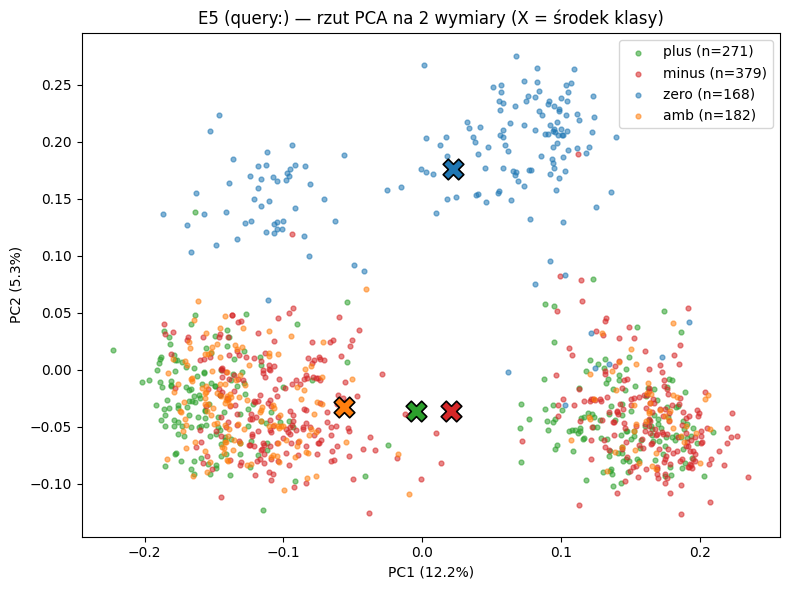

średnie współrzędne wg klasy:


,PC1,PC2
klasa,,
plus,-0.005,-0.037
minus,0.021,-0.036
zero,0.022,0.176
amb,-0.056,-0.033


temat (hotel?) a znak PC1:


PC1_dodatnie,False,True
temat_hotel,,
False,31,442
True,494,33


In [77]:
# Proszę zaimplementować PCA i przygotować wykres.

pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(dense_vecs["E5"])
var_pc1, var_pc2 = pca.explained_variance_ratio_[:2]
print(f"wariancja wyjaśniona: PC1={var_pc1:.3f}, PC2={var_pc2:.3f}, suma={var_pc1 + var_pc2:.3f}")

PALETTE = {"plus": "#2ca02c", "minus": "#d62728", "zero": "#1f77b4", "amb": "#ff7f0e"}
fig, ax = plt.subplots(figsize=(8, 6))
for cls, colour in PALETTE.items():
    mask = labels_arr == cls
    ax.scatter(coords[mask, 0], coords[mask, 1], s=12, alpha=0.55, color=colour, label=f"{cls} (n={mask.sum()})")
    centre = coords[mask].mean(axis=0)
    ax.scatter(*centre, s=220, color=colour, marker="X", edgecolors="black", linewidths=1.2)
ax.set_xlabel(f"PC1 ({var_pc1:.1%})")
ax.set_ylabel(f"PC2 ({var_pc2:.1%})")
ax.set_title("E5 (query:) — rzut PCA na 2 wymiary (X = środek klasy)")
ax.legend()
plt.tight_layout()
plt.show()

topic_hotel = sample_df["text"].str.contains(r"\bhotel|pokoj|pokój|recepcj|śniadani|nocleg", case=False, regex=True)
pca_summary = pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1],
                            "klasa": labels_arr, "temat_hotel": topic_hotel.to_numpy()})
print("średnie współrzędne wg klasy:")
display(pca_summary.groupby("klasa")[["PC1", "PC2"]].mean().reindex(["plus", "minus", "zero", "amb"]).round(3))
print("temat (hotel?) a znak PC1:")
pca_summary.assign(PC1_dodatnie=pca_summary["PC1"] > 0).groupby(["temat_hotel", "PC1_dodatnie"]).size().unstack(fill_value=0)


### Komentarz
Pierwsza składowa PC1 wyjaśnia 12.2% całkowitej zmienności embeddingów natomiast składowa druga PC2 wyjaśnia 5.3% wariancji. Sumarycznie, dwie pierwsze składowe wyjaśniają 17.5% wariancji danych, więc wykres pokazuje mały wycinek przestrzeni.

Klasa `zero` wyróżnia się znacznie na wykresie. Najwyraźniej modelowi `E5` najłątwiej jest wyodrębnić teksty naukowe, badawcze, ogółem, bez wyrazu i żadnej konkretnej opinii w środku. Natomiast w dolnej partii wykresu, wyraźnie mieszają się dokumenty poetykietowane z pomocą pozostałych klas, czyli: `plus`, `minus`, `amb`. Środki ich klastrów mieszczą się w podobnym regionie, jedynie środek dla klasy `amb` jest delikatnie wysunięty w lewo.

Wniosek jest jeden: model `E5` najmocniej koduje styl tekstu (`zero` vs opini, czyli `amb`+`plus`+`minus`).



# Zadanie 8: Analiza przypadków

Proszę przygotować tabelę zawierającą dokładnie 12 przypadków, które pokazują ograniczenia reprezentacji wektorowych.

Pierwsze 6 przypadków należy znaleźć w wynikach najbliższych sąsiadów lub wyszukiwania. Powinny to być przykłady, w których podobieństwo jest wysokie, ale wynik jest problematyczny z punktu widzenia sentymentu lub intencji zapytania.

Kolejne 6 przypadków należy przygotować jako pary kontrastowe, np.:

```text
Hotel jest dobry.
Hotel nie jest dobry.
```

Dla każdej pary proszę policzyć podobieństwo w MiniLM i E5.

Tabela powinna zawierać:

| nr | typ | tekst A | tekst B / wynik | MiniLM | E5 | Δ MiniLM | Δ E5 | komentarz |
|---:|---|---|---|---:|---:|---:|---:|---|

Cosinusy E5 są skupione wysoko, więc nie wolno porównywać bezwzględnych wartości MiniLM i E5. Δ to różnica między cosinusem pary a cosinusem pary niezwiązanej tematycznie (np. "Hotel jest dobry." i "Samochód jest szybki.") liczonym tym samym modelem.

W komentarzu proszę używać krótkich kategorii, np.:

- negacja;
- wspólny temat;
- wspólne słownictwo;
- podobna forma;
- różny sentyment;
- bardzo krótki tekst;
- inna.


In [78]:
# Proszę znaleźć 6 przypadków z danych, przygotować 6 par kontrastowych i zbudować tabelę 12 przypadków.

UNRELATED_PAIR = ("Hotel jest dobry.", "Samochód jest szybki.")

def pair_cosine(model_key, a, b):
    va, vb = embed_texts(model_key, [a, b])
    return round(float(va @ vb), 3)

baseline_cos = {key: pair_cosine(key, *UNRELATED_PAIR) for key in models}
print("cos pary niezwiązanej (baseline do Δ):", baseline_cos)

data_cases = []
seen_pairs = set()
for rep_name in ["MiniLM", "E5"]:
    top1 = NBR[rep_name][:, 0]
    scores = (tests[rep_name] * tests[rep_name][top1]).sum(axis=1)
    taken = 0
    for i in np.argsort(-scores):
        j = int(top1[i])
        key = frozenset((int(i), j))
        if labels_arr[i] != labels_arr[j] and key not in seen_pairs:
            seen_pairs.add(key)
            data_cases.append({"typ": f"sąsiad top-1 ({rep_name})", 
                               "lab_a": labels_arr[i],
                               "text_a": sample_df.loc[i, "text"], 
                               "lab_b": labels_arr[j],
                               "text_b": sample_df.loc[j, "text"], 
                               "komentarz": "wspólny temat, różny sentyment"})
            taken += 1
        if taken == 2:
            break
used_docs = set()
for rep_name in ["MiniLM", "E5"]:
    for i, (cls, q) in enumerate(QUERY_SET):
        top_doc = int(hits[rep_name][i][0])
        if labels_arr[top_doc] != cls and top_doc not in used_docs:
            used_docs.add(top_doc)
            data_cases.append({"typ": f"wyszukiwanie ({rep_name})", 
                               "lab_a": cls, 
                               "text_a": q,
                               "lab_b": labels_arr[top_doc], 
                               "text_b": sample_df.loc[top_doc, "text"],
                               "komentarz": ("wspólne słownictwo, różny sentyment"
                                             if rep_name == "MiniLM"
                                             else "nietrafiony wynik, różny temat")})
            break

CONTRAST_PARS = [
    ("negacja",             "Hotel jest dobry.",                                  "Hotel nie jest dobry."),
    ("negacja",             "Polecam tę przychodnię.",                            "Nie polecam tej przychodni."),
    ("różny sentyment",     "Lekarz był miły i pomocny.",                         "Lekarz był niemiły i bezużyteczny."),
    ("podobna forma",       "Pokój czysty, ale jedzenie słabe.",                  "Pokój słaby, ale jedzenie czyste."),
    ("inna: ironia",        "Rewelacja, czekaliśmy tylko trzy godziny na obiad.", "Obsługa była szybka, a jak szybko przynosiła rachunek."),
    ("bardzo krótki tekst", "Super!",                                             "Tragedia!"),
]

records = []
for case in data_cases[:6]:
    records.append({"typ": case["typ"],
                    "tekst A": f"[{case['lab_a']}] {case['text_a'][:140]}",
                    "tekst B / wynik": f"[{case['lab_b']}] {case['text_b'][:140]}",
                    "MiniLM": pair_cosine("MiniLM", case["text_a"], case["text_b"]),
                    "E5": pair_cosine("E5", case["text_a"], case["text_b"]),
                    "komentarz": case["komentarz"]})
for case_type, text_a, text_b in CONTRAST_PARS:
    records.append({"typ": f"para kontrastowa: {case_type}",
                    "tekst A": text_a, "tekst B / wynik": text_b,
                    "MiniLM": pair_cosine("MiniLM", text_a, text_b),
                    "E5": pair_cosine("E5", text_a, text_b),
                    "komentarz": case_type})

case_table = pd.DataFrame(records)
case_table.insert(0, "nr", range(1, len(case_table) + 1))
case_table["Δ MiniLM"] = (case_table["MiniLM"] - baseline_cos["MiniLM"]).round(3)
case_table["Δ E5"] = (case_table["E5"] - baseline_cos["E5"]).round(3)
case_table = case_table[["nr", "typ", "tekst A", "tekst B / wynik", "MiniLM", "E5", "Δ MiniLM", "Δ E5", "komentarz"]]
case_table

cos pary niezwiązanej (baseline do Δ): {'MiniLM': 0.14, 'E5': 0.834}


,nr,typ,tekst A,tekst B / wynik,MiniLM,E5,Δ MiniLM,Δ E5,komentarz
0,1,sąsiad top-1 (MiniLM),"[amb] Hotel niemal idealny - wspaniała , pomocna obsługa ( zwłaszcza restauracji - cudowni i kompetentni ludzie ) , przepyszne jedzenie ( na śniad","[plus] Świetny hotel , urządzony minimalistycznie , nowocześnie i ze smakiem . Pokoje sprzątane codziennie , jedzenie wg mnie bardzo dobre , ale to",0.866,0.909,0.726,0.075,"wspólny temat, różny sentyment"
1,2,sąsiad top-1 (MiniLM),"[amb] Gdyby m nie potrzebował czasem coś zjeść i nie próbował skorzystać z restauracji ocena była by pewnie "" doskonała "" - ale niestety próbował","[minus] Hotel piękny , w każdym detalu . Pokoje ok , mieli śmy pokój o podwyższony standardzie , był bardzo przestronny . Irytujący wentylator w łaz",0.864,0.912,0.724,0.078,"wspólny temat, różny sentyment"
2,3,sąsiad top-1 (E5),"[plus] Witam , do pani dr trafiła m 4 lata temu , kiedy mój syn kończył zerówkę . Wcześniej była m sceptycznie nastawiona do homeopatii i przez 2 l","[amb] Kiedyś przez kilka lat to była Pani dr pediatra mojego syna . Życzliwa , ujmująca , staranna , sympatyczna . Jednakże sposób leczenia alergi",0.683,0.950,0.543,0.116,"wspólny temat, różny sentyment"
3,4,sąsiad top-1 (E5),[plus] Ja do doktora Czapińskiego trafiła m 10 lat temu . Jestem mu wdzięczna za pomoc . Od bardzo dawna choruję na migrenę a dopiero podczas pierw,"[minus] Niestety , bardzo chciała m wystawić dobrą opinię Pani doktor , ponieważ szła m do niej na pierwszą wizytę z wielką nadzieją na pomoc . Kilk",0.800,0.945,0.660,0.111,"wspólny temat, różny sentyment"
4,5,wyszukiwanie (MiniLM),"[amb] Lekarz fachowy, ale wizyta była krótka i bardzo kosztowna.","[minus] była m prywatnie u tego Pana "" doktora "" . Może i ma opinię znakomitego specjalisty i nim jest , ale w kontakcie z pacjentem jest bardzo nie",0.771,0.916,0.631,0.082,"wspólne słownictwo, różny sentyment"
5,6,wyszukiwanie (E5),"[plus] Świetna klinika, lekarz bardzo kompetentny i serdeczny, gorąco polecam.",[minus] Zdecydowanie odradzam . Pokoje w rzeczywistosci nie mają nic wspólnego z tym co widzimy na stronie hotelu . Ja trafilam na malą ciemna klitk,0.010,0.817,-0.130,-0.017,"nietrafiony wynik, różny temat"
6,7,para kontrastowa: negacja,Hotel jest dobry.,Hotel nie jest dobry.,0.547,0.918,0.407,0.084,negacja
7,8,para kontrastowa: negacja,Polecam tę przychodnię.,Nie polecam tej przychodni.,0.251,0.915,0.111,0.081,negacja
8,9,para kontrastowa: różny sentyment,Lekarz był miły i pomocny.,Lekarz był niemiły i bezużyteczny.,0.290,0.927,0.150,0.093,różny sentyment
9,10,para kontrastowa: podobna forma,"Pokój czysty, ale jedzenie słabe.","Pokój słaby, ale jedzenie czyste.",0.958,0.994,0.818,0.160,podobna forma


# Zadanie 9: Interpretacja wyników

To zadanie nie wymaga nowej implementacji.

Na podstawie wyników zadań 1-8 proszę odpowiedzieć:

1. W jakich sytuacjach TF-IDF zachowywał się lepiej od reprezentacji gęstych?
2. W jakich sytuacjach przewagę miały MiniLM lub E5?
3. Czy wysoka wartość `purity@k` oznacza, że reprezentacja jest ogólnie "lepsza semantycznie"?
4. Czy model o najlepszym `Precision@10` musi być najlepszym wyborem do klasyfikacji sentymentu?
5. Jakie dwa ograniczenia eksperymentu najbardziej wpływają na interpretację wyników?

Odpowiedzi powinny odwoływać się do uzyskanych liczb i przykładów.

### Odpowiedzi
1. Ogółem, TF-IDF lepiej sobie radzi przy dokładnym dopasowywaniu słów i nazw. W zadaniu 4 dla dokumentu 1 (pierwszy przypadek), zwracał opinie bardzo podobne do reprezentacji z modelami. Ogólnie jest on dużo szybszy i zajmuje mniej miejsca, dlatego uważam, że w tym przypadku zachowywał się lepiej od reprezentacji gęstych.
2. Model `E5` miał przewagę w zadanu 5 w wyliczaniu czystości sąsiedztwa. Zwracał najlepsze wyniki dla dowolnego `k` spośród wszystkich reprezentacji.  Zwrócił on kolejno wyniki: 0.687, 0.665, 0.642, gdzie `MiniLM` zwrócił 0.602, 0.580, 0.558; natomiast TF-idf wypadł najgorzej z wynikami: 0.573, 0.559, 0.542
3. Niekoniecznie. Wszystko zależy od danych, ale ogólnie    purity   wylicza jedynie zgodność etykiet sentymentu w najbliższym sąsiedztwie. W związku z tym w zadaniu 5 widzimy, że największą `purity` ma klasa `zero` dla modelu `E5` (wartość 0.825), o czym świadczy również wykres PCA w następnym zadaniu. Wiadomości, teksty popularnonaukowe, informacje, mają podobny styl, a model `E5` dobrze rozumie neutralność, stąd w tej klasie będziemy mieć wysokie `purity`, nastomiast będzie niższe dla reszty klas. Jako neutralność rozumiem tutaj styl artykułów informacyjnych.
4. Nie. Najbardziej podobne teksty niekoniecznie muszą należeć do tej samej klasy. Jak widzimy na przykłądzie wyników w zadaniu 6, model `E5` zwracał najgorsze wartości `Precision@5` i `Precision@10` dla przykładowych zapytań, mimo, że wcześniej wydawał się `najmądrzejszym` w kontekście semantyki modelem oceniając 'na oko'.
5. Małe ilości danych do testów: mały benchmark 1000 dokumentów, tylko 8 zapytań napisanych przeze mnie. Drugim problemem jest dobranie modeli: o ile `E5` jest dobrze dobrane do zbioru, to `MiniLM` obcina 76.7% tesktów, więc porównywanie tych modeli jest niekorzystne już na początku, bo `MiniLM` przegrywa technologicznie ze względu na dużo mniejsze okno kontekstu.

# Zadanie 10: Decyzja projektowa

To zadanie nie wymaga nowej implementacji.

Proszę wybrać reprezentację dla każdego z trzech zastosowań:

1. szybkie wyszukiwanie po dokładnych nazwach i terminach;
2. wyszukiwanie semantyczne parafraz;
3. przyszły system RAG.

Dla każdego zastosowania proszę podać:

- wybraną reprezentację;
- jeden wynik ilościowy (jakość lub koszt) uzasadniający decyzję;
- jeden obserwowany przypadek błędu lub ograniczenie;
- koszt, który należy zaakceptować.

Na końcu proszę odpowiedzieć jednym akapitem na pytanie:

**Dlaczego embeddingu nie należy utożsamiać ze "znaczeniem tekstu"?**

### Odpowiedzi
1. TF-IDF. Tworzenie to 0.229 ms na dokument, ok. 13 razy szybciej niż MiniLM (2.943 ms) i 200 razy szybciej niż E5 (26.891 ms). Dodatkowo nie trzeba GPU. Ograniczenia tf-idf to: parafraza "Obiekt noclegowy zrobił świetne wrażenie" ma z "Hotel był bardzo dobry" cosinus 0, a "dobry" i "zły" hotel mają 0.63, i słowa odmienione to już słowa niepodobne; ale jeżeli chcemy wyszukiwanie dokładnych nazw to właśnie tego szukamy.
2. MiniLM. W zadaniu 2 dla parafrazy zwrócił podobieństwo 0.7494, natomiast dla negacji zwrócił podobieństwo 0.3783. Jest on dobrym modelem. Semantycznie gorzej ocenia niż E5, ale jest dużo szybszy a znaczenie już w większości przypadków 'łapie'.
3. E5. Zwraca najlepsze purity (0.687, 0.665, 0.642), ma największe okno kontekstu: 512 tokenów (obcina tylko 3.7% tekstów) i jest trenowany pod query/passage. Niestety należy zwrócić uwagę również, że ma duże koszta bo ma najdłuższe procesowanie dokumentu i przez to też wymaga GPU.

> Embedding jest wektorową reprezentacją tekstu w przestrzeni ukształtowanej przez zadanie treningowe modelu, ale nie jest pełnym „znaczeniem” tekstu. W przeprowadzonym eksperymencie E5 i MiniLM grupowały teksty głównie według tematu i stylu. Dlatego przeciwne opinie o tym samym hotelu mogły być bardziej podobne niż neutralne teksty dotyczące różnych tematów. Modele słabo reagowały także na samą negację — dodanie słowa „nie” nieznacznie zmieniało wartość podobieństwa cosinusowego **na plus**. Co jest totalnie bez sensu. np.: Hotel jest dobry / Hotel nie jest dobry: MiniLM zwrócił podobieństwo 0.547, a E5 0.918.

# Karta modelu embeddingowego

Proszę wybrać jeden z dwóch modeli gęstej reprezentacji jako model rekomendowany do dalszych laboratoriów i utworzyć:

```text
artifacts/embedding_model_card.md
```

Karta powinna zawierać:

## Model
- nazwa checkpointu;
- wymiar reprezentacji;
- sposób normalizacji;
- wymagane prefiksy wejścia, jeśli dotyczy.

## Dane
- użyty zbiór;
- wielkość próbki;
- odsetek tekstów obciętych przez okno modelu;
- sposób doboru próbki.

## Koszt
- czas utworzenia reprezentacji;
- ms/dokument;
- rozmiar reprezentacji w pamięci.

## Jakość sąsiedztwa
- `purity@1`;
- `purity@5`;
- `purity@10`.

## Wyszukiwanie
- `Precision@5`;
- `Precision@10`.

## Analiza jakościowa
- najważniejsze obserwacje z PCA;
- dominujące typy błędów z analizy 20 przypadków.

## Zastosowanie
- do jakich zadań model jest rekomendowany;
- do jakich zadań nie należy go wybierać wyłącznie na podstawie tego laboratorium.

## Ograniczenia
- ograniczenia danych;
- ograniczenia benchmarku;
- ograniczenia samej reprezentacji.


In [79]:
# Karta modelu jest generowana z policzonych wyżej zmiennych, aby liczby były spójne z wynikami.
from datetime import date

CARD_MODEL = "E5"  # intfloat/multilingual-e5-small — rekomendowany (najlepsze purity i Precision, większe okno)
ov = dense_overview.set_index("model")
cost = cost_table.set_index("reprezentacja")
pur = purity_table.set_index("reprezentacja")
ret = retrieval_table

e5_trunc = ov.loc["E5", "% obciętych (próbka)"]
mini_trunc = ov.loc["MiniLM", "% obciętych (próbka)"]

card = f"""# Karta modelu embeddingowego

Model rekomendowany do dalszych laboratoriów: **intfloat/multilingual-e5-small**.
Data: {date.today().isoformat()}.

## Model
- checkpoint: `intfloat/multilingual-e5-small`
- wymiar reprezentacji: {int(ov.loc["E5", "wymiar"])}
- normalizacja: L2 (`normalize_embeddings=True`), średnia długość wektora ≈ {ov.loc["E5", "śr. norma"]}
- wymagane prefiksy: `query: ` dla zapytań i zadań symetrycznych, `passage: ` dla dokumentów w wyszukiwaniu

## Dane
- zbiór: PolEmo 2.0 (`artifacts/polemo2_clean.parquet`), wyłącznie split train
- wielkość próbki: {len(sample_df)} dokumentów
- odsetek tekstów obciętych przez okno modelu (max_seq_length={int(ov.loc["E5", "max_seq_length"])}): {e5_trunc}%
- dobór próbki: `train_test_split` ze stratyfikacją po klasie, `random_state={RANDOM_STATE}` (deterministyczny)

## Koszt (urządzenie: {DEVICE})
- czas utworzenia reprezentacji: {cost.loc["E5", "czas [s]"]} s
- ms/dokument: {cost.loc["E5", "ms/dokument"]}
- rozmiar reprezentacji w pamięci: {cost.loc["E5", "rozmiar [MB]"]} MB ({int(cost.loc["E5", "liczba wymiarów"])} wymiarów, typ gęsty)

## Jakość sąsiedztwa (purity, punkt odniesienia losowy ≈ {round(baseline_purity, 3)})
- purity@1: {pur.loc["E5", "purity@1"]}
- purity@5: {pur.loc["E5", "purity@5"]}
- purity@10: {pur.loc["E5", "purity@10"]}

## Wyszukiwanie (8 zapytań, etykieta sentymentu jako przybliżona relewancja)
- Precision@5: {ret.loc["E5", "Precision@5"]}
- Precision@10: {ret.loc["E5", "Precision@10"]}

## Analiza jakościowa
- PCA: dwie pierwsze składowe wyjaśniają jedynie {var_pc1 + var_pc2:.1%} wariancji; PC2 wyróżnia klasę `zero` (styl newsowy). Klasy `plus`, `minus`, `amb` silnie się mieszają — sentyment nie jest kodowany w pierwszych składowych.
- dominujące typy błędów (tabela 12 przypadków): różny sentyment przy wspólnym temacie, słaba wrażliwość na negację oraz zamianę słów (podobna forma); wszystkie pary kontrastowe mają Δ > 0 względem pary niezwiązanej.

## Zastosowanie
- rekomendowany do: wyszukiwania semantycznego / retrievalu (RAG), grupowania tematycznego, wyszukiwania parafraz — dzięki oknu 512 tokenów ({e5_trunc}% obciętych vs {mini_trunc}% dla MiniLM) i najlepszemu purity.
- nie należy wybierać wyłącznie na podstawie tego laboratorium do: klasyfikacji sentymentu (wymaga trenowanego klasyfikatora; TF-IDF+LR z Lab 2 miał macro-F1 ≈ 0,80) ani do wyszukiwania po dokładnych nazwach/terminach (tańszy i skuteczniejszy bywa TF-IDF).

## Ograniczenia
- dane: tylko split train PolEmo, próbka {len(sample_df)} dokumentów; klasa `zero` to głównie teksty prasowe, co sztucznie zawyża purity.
- benchmark: 8 ręcznie napisanych zapytań: wyniki Precision@k bardzo słabe dla tego modelu, ale to najwyyraźniej ze względu na słabo dobrane zapytania.
- reprezentacja: cosinusy E5 są skupione wysoko (nieporównywalne bezwzględnie z MiniLM), model słabo widzi negację, a okno tokenów ucina część dłuższych tekstów.
"""

card_path = ARTIFACTS / "embedding_model_card.md"
card_path.write_text(card, encoding="utf-8")
print("Zapisano", card_path, "| rekomendowany model:", CARD_MODEL)


Zapisano artifacts/embedding_model_card.md | rekomendowany model: E5


# Wnioski

Na koniec pracy proszę zapisać krótkie wnioski. Każdy wniosek powinien wynikać z wykonanego eksperymentu i zawierać odwołanie do wyniku liczbowego, obserwacji albo konkretnego przypadku.

Nie należy przepisywać definicji TF-IDF, embeddingów ani podobieństwa cosinusowego.

### Wnioski
1. Jak zobrazowalimy w zadaniu 1. w zestawie zdań 2., sprawdzanie podobiestwa tekstów poprzez TF-IDF nie jest najlepszym rozwiązaniem semantycznym. Takie rozwiązanie nie bierze pod uwagę sensu tekstów tylko zwyczajne występowanie słów w dokumentach.
2. Przy wykorzystaniu modeli E5 oraz MiniLM, uzyskane podobieństwo zdań dla obu modeli jest taka jak u człowieka. Najbardziej podobne są zdania A i B, Następnie w kolejności są zdania A i C a na samym końcu zdania B i C. Oba modele zwracają tę samą kolejność. Dobrze oddają podobieństwo weług którego ocenia człowiek. Dają dużą poprawę 'zrozumienia' tekstu w porównaniu do metody TF-IDF.
3. Należy zawsze dobrać model do danych. Różne modele mają różne wielkości okien kontekstu. Jak zoabczyliśmy w zadaniu drugim, dla modelu `MiniLM` maksymalna ilość tokenów którą może przeprocesować dla pojedynczego tekstu to 128 tokenów, natomiast model `E5` ma okno o wielkości 512. Różnica jest 4krotna.
4. W zadaniu 3 widzimy również, że że kodowanie tekstów przez E5 trwa dłużej niż przez MiniLM. Jedną z przyczyn jest większe okno wejściowe E5 (max_seq_length=512 zamiast 128), dzięki któremu E5 przetwarza więcej tokenów, podczas gdy MiniLM obcina dłuższe teksty.
5. W zadaniu 4 zaobserwowaliśmy, że reprezentacja TF-IDF zwraca dużo mniejsze poedobieństwa tekstu w porównaniu do reprezentacji modelowych. Np. dla dokumentu nr 12 o badaniach środowiskowych, TF-IDF zwrócił jako podobne dokumenty po prostu dokumenty, które miały wspólne słowa z porównywanym. Np. dokument nr 572 (`uniwersytet`) albo też dokument nr 302 w którym widizmy powtarzający się skrót `prof.`. Tematycznie te teksty nie byłī za bardzo podobne. Po prostu zawierały 'słowa klucz'
6. W Zadaniu 5 zaobserwowaliśmy, że czystości węzłów dla każdej wartości `k` najbliższych sąsiadów są najmniejsze dla `TF-IDF`, następnie większe czystości są dla `MiniLM` i największe czystości węzłów są dla modelu `E5`. Wynik może wynikać z lepszego uchwycenia informacji semantycznych przez embeddingi oraz z większego okna wejściowego E5, które ogranicza obcinanie długich tekstów. Mniejsze okno ma MiniLM, natomiast TF-IDF nie "rozumie" tesjktu tak jak reprezentacje modelowe, dlatego ma najmniej powtarzajających się etykiet w sąsiedztwie.
7. Bardzo zaskoczył mnie wyniki w Zadaniu 6, gdzie reprezentacja dotychczas najlepsza pod każdym względem, czyli ta wykorzystująca model `E5`, zwróciła najgorsze precision dla przykładowych 8 zapytań. Możliwe, że to przez akurat takie zapytania przykładowe a nie inne. Nie oceniałabym tego wyniku na minus `E5` tylko bardziej jako na minus doboru moich zpaytań do naszego zbioru danych.
8. Na wykresie PCA możemy zaobserwować jak łatwo modelowi `E5` rozróżnić jest teksty z etykietą `zero`, które mają wyraźnie inny wydźwięk (bardziej reporterski, badawczy) od reszty. Teksty z opiniami mieszają się między sobą. Wniosek jest jeden: model `E5` najmocniej koduje styl tekstu (`zero` vs opinie, czyli `amb`+`plus`+`minus`).

# Warunki zaliczenia laboratorium

Laboratorium jest ukończone, jeśli zawiera:

- [ ] własną implementację eksperymentu TF-IDF i podobieństwa cosinusowego;
- [ ] reprezentacje MiniLM i E5;
- [ ] deterministyczną próbkę danych;
- [ ] benchmark czasu i pamięci trzech reprezentacji;
- [ ] implementację wyszukiwania najbliższych sąsiadów;
- [ ] `purity@1`, `purity@5`, `purity@10`;
- [ ] osiem zapytań w benchmarku wyszukiwania;
- [ ] własną implementację `Precision@k`;
- [ ] `Precision@5` i `Precision@10`;
- [ ] wizualizację PCA;
- [ ] tabelę 12 przypadków błędów i par kontrastowych;
- [ ] sprawdzenie okna modeli (`max_seq_length`) i odsetka obciętych tekstów;
- [ ] purity z punktem odniesienia (losowi sąsiedzi) i per klasa;
- [ ] odpowiedzi do zadania interpretacyjnego (Zadanie 9);
- [ ] plik `artifacts/embedding_model_card.md`;
- [ ] od pięciu do ośmiu wniosków końcowych.